# Global masks for drought indices

In [6]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cmocean
import matplotlib
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from matplotlib.lines import Line2D
import cartopy
import cartopy.crs as ccrs
import numpy as np
import os 
import glob
import sys
import datetime as dt
import pandas as pd
import geopandas as gpd
import calendar
import netCDF4 as nc4
import xarray as xr
from dateutil import relativedelta
from datetime import timedelta
import regionmask
import string
from xhistogram.xarray import histogram
#xr.set_options(display_expand_attrs=False)

sys.path.insert(0, '..')
sys.path.insert(0, '../..')

In [7]:
from helpers.helpers_plotting import create_diverging_colorscheme, hex2rgb
from helpers.geodata import calculate_gridarea

## Read / Create masks

### Settings

In [8]:
vpath = "/ec/vol/centaur/nejk/veg_data"
vfile1=f"{vpath}/geff-data/share/geff/GlobalFuelMap_v1_N320_remap_025.nc"
vfile2=f"{vpath}/c32_data/swvl1_l5_mask_202408.nc"

### Mask barren land (Koeppen-Geiger)

In [10]:
vegetation_data = xr.open_dataset(vfile1)
print(vegetation_data)

<xarray.Dataset> Size: 4MB
Dimensions:          (time: 1, lon: 1440, lat: 721, height: 1)
Coordinates:
  * time             (time) datetime64[ns] 8B 2007-03-23T12:00:00
  * lon              (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * lat              (lat) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * height           (height) float64 8B 0.0
Data variables:
    param29.212.192  (time, height, lat, lon) float32 4MB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Tue Jun 11 09:01:25 2024: cdo --eccodes -f nc copy -remapnn...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...


<xarray.DataArray 'param29.212.192' (lat: 721, lon: 1440)> Size: 8MB
array([[1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       ...,
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1]])
Coordinates:
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
  * lat      (lat) float64 6kB 90.0 89.75 89.5 89.25 ... -89.5 -89.75 -90.0


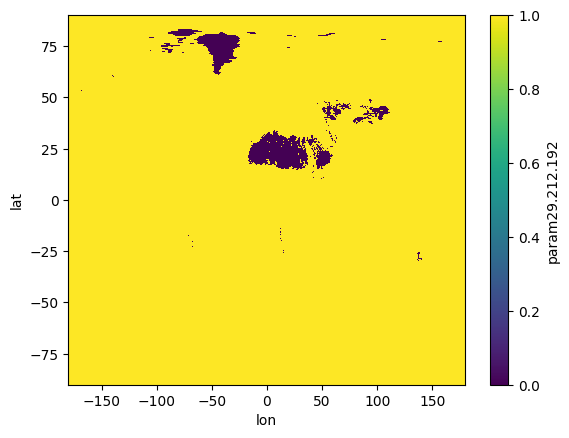

In [11]:
# less than 5% vegetation
#barren_mask = xr.where( (vegetation_data['cvh']+vegetation_data['cvl']) <= 0.05, 0, 1).isel(time=0).drop_vars('time')
# based on fire-koeppen-geiger mask
barren_mask = xr.where( (vegetation_data['param29.212.192']) == 22, 0, 1).isel(time=0, height=0).drop_vars(['time','height'])
barren_mask = xr.where( (vegetation_data['param29.212.192']) == 24, 0, barren_mask).isel(time=0, height=0).drop_vars(['time','height'])
#barren_mask = barren_mask.rename({'longitude': 'lon','latitude': 'lat'})
barren_mask.plot()
print(barren_mask)

## Mask drought indicator

### Ultimate mask

In [28]:
#drought_2d_masked = xr.where(signmask_static == 0, np.nan, drought_2d_masked)
#drought_2d_masked = xr.where(pzeromask_static == 0, np.nan, drought_2d_masked)
ultimate_mask = xr.where(drought_2d_masked == np.nan, np.nan, 1)
ultimate_mask = xr.where(pzeromask_static == 0, 0, ultimate_mask)
ultimate_mask = xr.where(barren_mask == 0, 0, ultimate_mask)
ultimate_mask = xr.where(signmask_static == 0, 0, ultimate_mask)

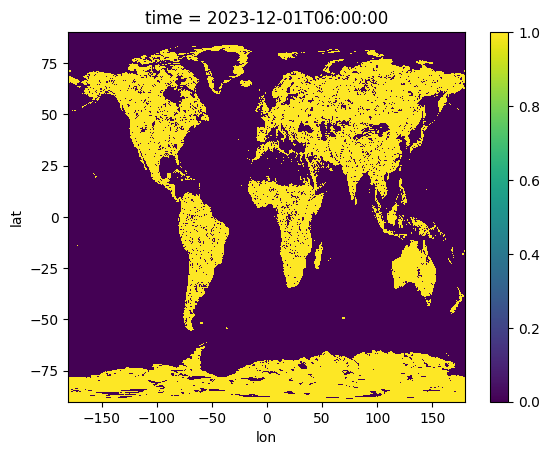

In [29]:
ultimate_mask.plot()

In [ ]:
### Mask drought indicator

In [ ]:
drought_2d_masked = xr.where(ultimate_mask == 0, -9999, drought_2d_masked)
drought_2d_masked = xr.where(drought_2d[f'{indicator}{window}'].isel(time=0) == -9999, np.nan, drought_2d_masked)

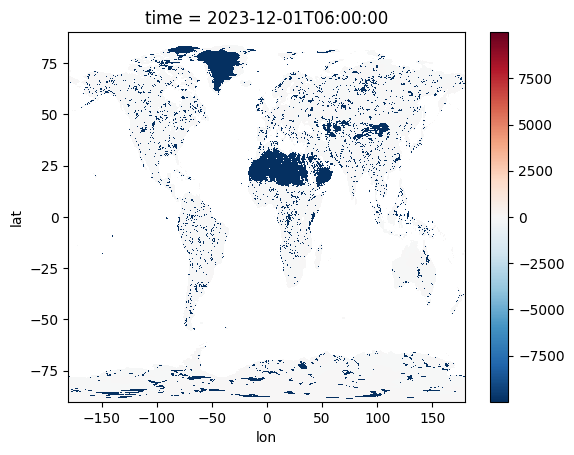

In [30]:
drought_2d_masked.plot()

## Masked figure

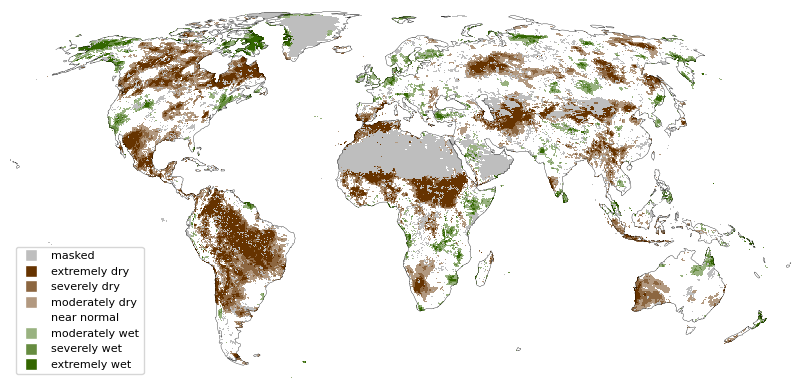

In [26]:
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
worldmap_drought(drought_2d_masked, 
                 collist_hex = mycollisthex, 
                 levels = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000],
                 legnames = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
                 figname=f"figures/{indicator}{window}_{distribut}_global_{dataset}_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{yyyy}{str(mm).zfill(2)}.png",
                 latlines=[-30,30], plot_latlines=False, mytitle="")

## Plot function with mask

In [35]:
mylevels = [-10000,-100,-2,-1.5,-1,1,1.5,2,100]
masked=hex2rgb('bebebe')
ext_wet=hex2rgb('336600')
sev_wet=hex2rgb('668c40')
mod_wet=hex2rgb('99b280')
near_norm=hex2rgb('bebebe')
mod_dry=hex2rgb('b29980')
sev_dry=hex2rgb('8c6640')
ext_dry=hex2rgb('663300')
#mycollist = [ext_dry, sev_dry, mod_dry, near_norm, mod_wet, sev_wet, ext_wet]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]
print(mycollist)

def read_mask_map(indicator, window, 
                  yyyy=2023, mm=3,
                  distribut='gamma',
                  stream='moda', dataset='era5',
                  ref_syyyy=1991, ref_eyyyy=2020,
                  mask_pzero=False,
                  pzero_thresh=0.1,
                  mask_significance=False, 
                  mask_vegetation=True,
                  barren_thresh=0.05,
                  collist_hex = ['#663300','#8c6640','#b29980','#bebebe','#99b280','#668c40','#336600'],
                  legnames = ["extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
                  levels = [-1000,-2,-1.5,-1,1,1.5,2,1000],
                  mytitle = ""):
    
    ifile=f"/ec/vol/centaur/nejk/drought_monitor/{indicator.lower()}/{indicator.lower()}{window}/{indicator}{window}_{distribut}_global_{dataset}_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{yyyy}{str(mm).zfill(2)}.nc"
    sfile=f"/ec/vol/centaur/nejk/drought_monitor/{indicator.lower()}/{indicator.lower()}{window}/parameter/{indicator}{window}_{distribut}_global_{dataset}_{stream}_ref{ref_syyyy}to{ref_eyyyy}_params_updated.nc" 
    #vfile=f"/scratch/nejk/droughts_hist/vegetation_cover_high_low.nc"
    vfile=f"/scratch/nejk/geff-data/share/geff/GlobalFuelMap_v1_N320_remap_025.nc"
        
    drought_2d = xr.open_dataset(ifile)
    drought_2d_masked = xr.where(drought_2d[f'{indicator}{window}'].isel(time=0) == -9999, np.nan, drought_2d[f'{indicator}{window}'].isel(time=0))

    if mask_pzero or mask_significance:
        staticdata = xr.open_dataset(sfile)
    if mask_pzero:
        pzeromask = xr.where( staticdata['pzero'].isel(time=mm-1) >= pzero_thresh, 0, 1)
        drought_2d_masked = xr.where(pzeromask == 0, -9999, drought_2d_masked)
    if mask_significance:
        signfmask = xr.where( staticdata['significance'].isel(time=mm-1) == 0, 0, 1 )
        drought_2d_masked = xr.where(signfmask == 0, -9999, drought_2d_masked)

    if mask_vegetation:
        vegetation_data = xr.open_dataset(vfile)
        #vfile=f"/scratch/nejk/droughts_hist/vegetation_cover_high_low.nc"
        #barren_mask = xr.where( (vegetation_data['cvh']+vegetation_data['cvl']) <= barren_thresh, 0, 1).isel(time=0).drop_vars('time')
        #vfile=f"/scratch/nejk/geff-data/share/geff/GlobalFuelMap_v1_N320_remap_025.nc"
        barren_mask = xr.where( (vegetation_data['param29.212.192']) == 22, 0, 1).isel(time=0, height=0).drop_vars(['time','height'])
        barren_mask = xr.where( (vegetation_data['param29.212.192']) == 24, 0, barren_mask).isel(time=0, height=0).drop_vars(['time','height'])
        barren_mask = barren_mask.rename({'longitude': 'lon','latitude': 'lat'})
        drought_2d_masked = xr.where(barren_mask == 0, -9999, drought_2d_masked)
        
    # reset ocean to np.nan
    drought_2d_masked = xr.where(drought_2d[f'{indicator}{window}'].isel(time=0) == -9999, np.nan, drought_2d_masked)

    worldmap_drought(drought_2d_masked,
                     levels = levels,
                     legnames = legnames,
                     collist_hex = collist_hex, 
                     figname=f"figures/{indicator}{window}_{distribut}_global_{dataset}_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{yyyy}{str(mm).zfill(2)}.png",
                     mytitle = mytitle)


[(0.4, 0.2, 0.0), (0.5490196078431373, 0.4, 0.25098039215686274), (0.6980392156862745, 0.6, 0.5019607843137255), (0.7450980392156863, 0.7450980392156863, 0.7450980392156863), (0.6, 0.6980392156862745, 0.5019607843137255), (0.4, 0.5490196078431373, 0.25098039215686274), (0.2, 0.4, 0.0)]


## Final figures

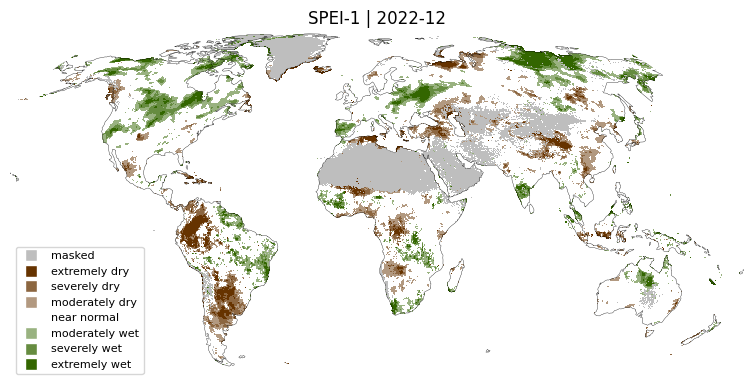

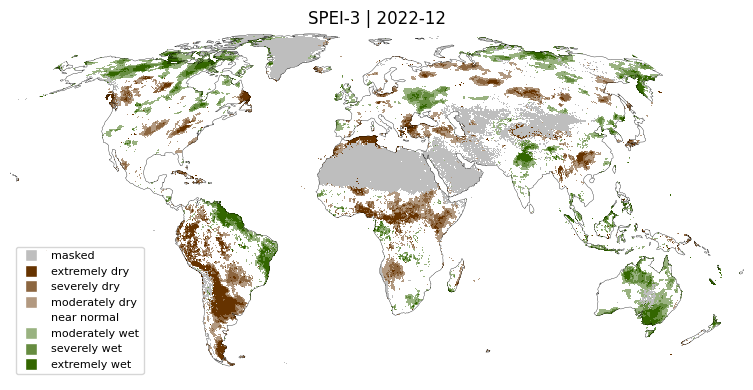

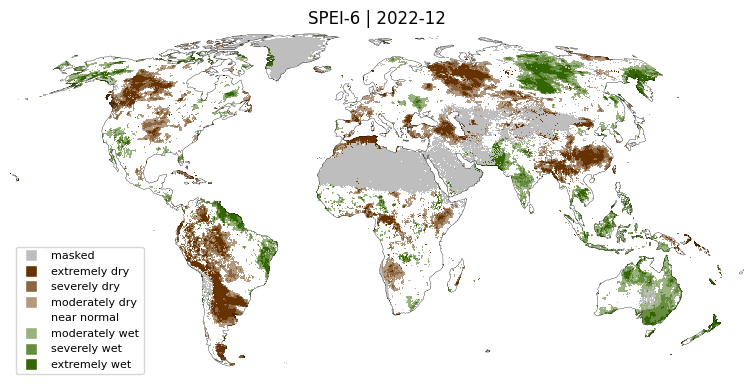

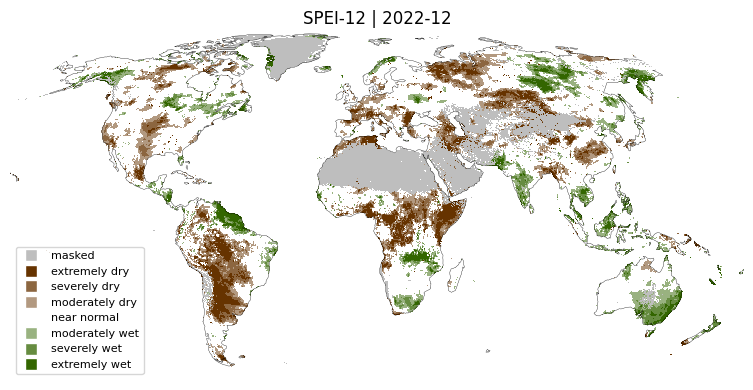

FileNotFoundError: [Errno 2] No such file or directory: b'/ec/vol/centaur/nejk/drought_monitor/spei/spei24/parameter/SPEI24_genlogistic_global_era5_moda_ref1991to2020_params_updated.nc'

In [40]:
for window in [1,3,6,12,24,36,48]:
    for iyyyy in range(2022, 2023):
        for im in [12]:
            read_mask_map("SPEI", window, 
              yyyy=iyyyy, mm=im,
              dataset='era5',
              collist_hex=mycollisthex, 
              legnames=legnames,
              distribut='genlogistic',
              mask_pzero=True,
              mytitle=f"{indicator}-{window} | {iyyyy}-{im}")

In [ ]:
# plot dry only
read_mask_map("SPEI", 12, 
              yyyy=2023, mm=11,
              dataset='era5',
              distribut='genlogistic',
              mask_pzero=False,
              collist_hex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff'],
              legnames = ["masked", "extremely dry", "severely dry", "moderately dry"," "],
              levels = [-10000,-1000,-2,-1.5,-1,1000])

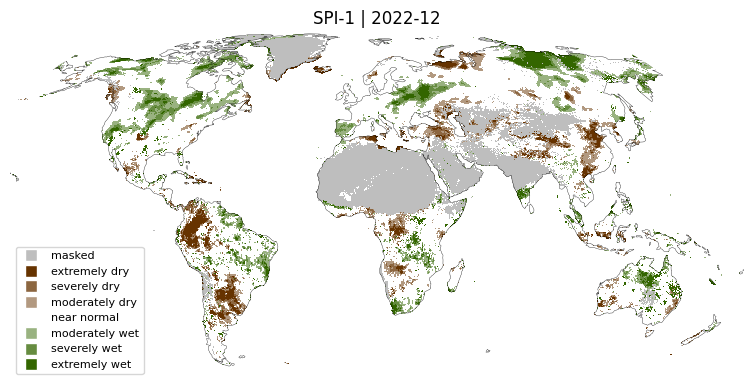

In [44]:
indicator="SPI"
window=1
read_mask_map(indicator, window, 
              yyyy=2022, mm=12,
              collist_hex=['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600'],
              legnames=["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
              dataset='era5',
              distribut='gamma',
              mask_pzero=True,
              mytitle=f"{indicator}-{window} | {iyyyy}-{im}")

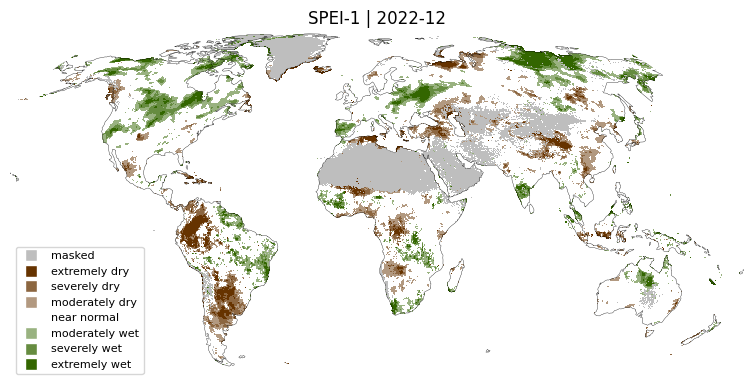

In [45]:
indicator="SPEI"
window=1
read_mask_map(indicator, window, 
              yyyy=2022, mm=12,
              collist_hex=['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600'],
              legnames=["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"],
              dataset='era5',
              distribut='genlogistic',
              mytitle=f"{indicator}-{window} | {iyyyy}-{im}")